# A/B tests: counts and moments

The simplest place where sufficiency pays. A conversion experiment logs one Bernoulli outcome per
user, but the likelihood for a conversion rate $p$ only ever sees two numbers per arm:

$$\prod_{i=1}^{n} p^{y_i}(1-p)^{1-y_i} = p^{k}(1-p)^{n-k}, \qquad T(y) = (n, k).$$

For a continuous outcome (revenue per user) under a Normal model, the triple
$T(y) = (n, \bar y, SS)$ with $SS = \sum_i (y_i-\bar y)^2$ is sufficient for $(\mu, \sigma)$:

$$\sum_i \log \mathcal N(y_i \mid \mu,\sigma) = -\tfrac{n}{2}\log(2\pi\sigma^2) - \frac{SS + n(\bar y-\mu)^2}{2\sigma^2}.$$

We fit each model twice, once on the raw rows and once on $T(y)$, and check that the posteriors
coincide while the wall time collapses.

In [1]:
import time
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(101)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)


def timed_fit(model, label, n_rows, **kw):
    """Sample a model and return (idata, one-row timing record)."""
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    return idata, {"model": label, "rows in likelihood": n_rows, "wall time (s)": round(secs, 1),
                   "min ESS/s": round(ess / secs, 1)}

## Conversions: Bernoulli rows vs Binomial counts

Two arms, 400,000 users each, baseline conversion 4.0% and a treatment lift to 4.2%.

In [2]:
n_per_arm = 400_000
true_p = np.array([0.040, 0.042])
arm = np.repeat([0, 1], n_per_arm)
y = rng.binomial(1, true_p[arm])

# the sufficient statistic: trials and successes per arm
counts = pd.DataFrame({"arm": arm, "y": y}).groupby("arm").y.agg(n="count", k="sum")
counts

,n,k
arm,,
0,400000,16027
1,400000,16602


In [3]:
coords = {"arm": ["control", "treatment"]}

with pm.Model(coords=coords) as bern_full:
    p = pm.Beta("p", 1, 1, dims="arm")
    pm.Deterministic("lift", p[1] - p[0])
    pm.Bernoulli("y", p=p[arm], observed=y)

with pm.Model(coords=coords) as bern_suff:
    p = pm.Beta("p", 1, 1, dims="arm")
    pm.Deterministic("lift", p[1] - p[0])
    pm.Binomial("k", n=counts.n.values, p=p, observed=counts.k.values)

idata_bf, rec_bf = timed_fit(bern_full, "Bernoulli, raw rows", len(y))
idata_bs, rec_bs = timed_fit(bern_suff, "Binomial, (n, k) per arm", len(counts))

NUTS[nutpie]: [p]
NUTS[nutpie]: [p]


Both models share the Beta prior, and Beta–Binomial is conjugate, so we also have the exact answer:
$p_a \mid y \sim \text{Beta}(1 + k_a, 1 + n_a - k_a)$. No sampler needed at all; that is the
limiting case of compression.

In [4]:
post_a = 1 + counts.k.values
post_b = 1 + counts.n.values - counts.k.values
exact_lift = rng.beta(post_a[1], post_b[1], 20_000) - rng.beta(post_a[0], post_b[0], 20_000)

## Revenue per user: raw Normal rows vs $(n, \bar y, SS)$

200,000 users per arm, revenue with mean 10.0 vs 10.15 and standard deviation 6.

In [5]:
n_rev = 200_000
true_mu, true_sigma = np.array([10.0, 10.15]), 6.0
arm_r = np.repeat([0, 1], n_rev)
rev = rng.normal(true_mu[arm_r], true_sigma)

moments = (pd.DataFrame({"arm": arm_r, "rev": rev}).groupby("arm").rev
           .agg(n="count", ybar="mean", SS=lambda s: ((s - s.mean()) ** 2).sum()))
moments

,n,ybar,SS
arm,,,
0,200000,10.009827,7.188578e+06
1,200000,10.154574,7.182468e+06


In [6]:
with pm.Model(coords=coords) as norm_full:
    mu = pm.Normal("mu", 10, 5, dims="arm")
    sigma = pm.HalfNormal("sigma", 10)
    pm.Deterministic("delta", mu[1] - mu[0])
    pm.Normal("rev", mu[arm_r], sigma, observed=rev)

n_, ybar_, SS_ = (moments[c].values for c in ["n", "ybar", "SS"])
with pm.Model(coords=coords) as norm_suff:
    mu = pm.Normal("mu", 10, 5, dims="arm")
    sigma = pm.HalfNormal("sigma", 10)
    pm.Deterministic("delta", mu[1] - mu[0])
    # exact Normal log-likelihood written in terms of the sufficient statistics
    loglik = -0.5 * n_ * pm.math.log(2 * np.pi * sigma**2) - (SS_ + n_ * (ybar_ - mu) ** 2) / (2 * sigma**2)
    pm.Potential("loglik", loglik.sum())

idata_nf, rec_nf = timed_fit(norm_full, "Normal, raw rows", len(rev))
idata_ns, rec_ns = timed_fit(norm_suff, "Normal, (n, ȳ, SS) per arm", len(moments))

NUTS[nutpie]: [mu, sigma]
NUTS[nutpie]: [mu, sigma]


## Same posterior, different cost

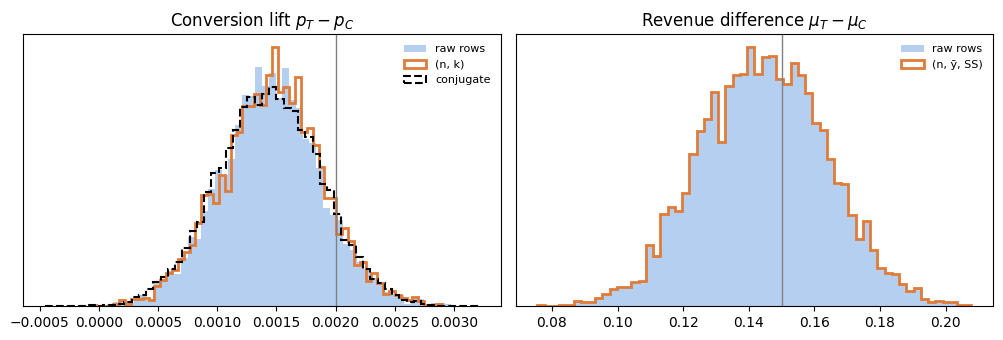

In [7]:
#| label: fig-ab-equiv
#| fig-cap: "Posterior for the treatment effect from raw rows (filled) and from the sufficient statistics (line). Left: conversion lift, with the exact conjugate posterior dashed. Right: revenue difference."
def draws(idata, var):
    return idata.posterior[var].values.ravel()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
ax = axes[0]
ax.hist(draws(idata_bf, "lift"), bins=60, density=True, alpha=0.35, color="#2a78d6", label="raw rows")
ax.hist(draws(idata_bs, "lift"), bins=60, density=True, histtype="step", lw=2, color="#e07b39", label="(n, k)")
ax.hist(exact_lift, bins=60, density=True, histtype="step", lw=1.5, ls="--", color="k", label="conjugate")
ax.axvline(true_p[1] - true_p[0], color="grey", lw=1)
ax.set_title("Conversion lift $p_T - p_C$")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.hist(draws(idata_nf, "delta"), bins=60, density=True, alpha=0.35, color="#2a78d6", label="raw rows")
ax.hist(draws(idata_ns, "delta"), bins=60, density=True, histtype="step", lw=2, color="#e07b39", label="(n, ȳ, SS)")
ax.axvline(true_mu[1] - true_mu[0], color="grey", lw=1)
ax.set_title(r"Revenue difference $\mu_T - \mu_C$")
ax.legend(frameon=False, fontsize=8)
for a in axes:
    a.set_yticks([])
plt.tight_layout()
plt.show()

In [8]:
#| label: tbl-ab-speed
#| tbl-cap: "Rows the likelihood touches, wall time (compile + sample, 4 chains × 2,000 iterations) and bulk ESS per second."
speed = pd.DataFrame([rec_bf, rec_bs, rec_nf, rec_ns])
speed["posterior mean of effect"] = [draws(i, v).mean().round(4) for i, v in
                                     [(idata_bf, "lift"), (idata_bs, "lift"), (idata_nf, "delta"), (idata_ns, "delta")]]
speed

,model,rows in likelihood,wall time (s),min ESS/s,posterior mean of effect
0,"Bernoulli, raw rows",800000,45.9,93.4,0.0015
1,"Binomial, (n, k) per arm",2,1.2,3128.6,0.0015
2,"Normal, raw rows",400000,10.8,536.3,0.1445
3,"Normal, (n, ȳ, SS) per arm",2,1.1,5212.6,0.1445


## What you give up

- **Row-level diagnostics.** A `pm.Potential` contributes to the posterior but not to
  `log_likelihood` or posterior predictive sampling, so LOO and PPCs on individual users are gone.
  For the Binomial version they survive, but at the level of the arm, not the user.
- **Covariates.** $(n, k)$ is sufficient only *within* a cell of identical covariates. Add a continuous
  covariate and the strata dissolve; categorical covariates just multiply the number of cells.
- **The model is now load-bearing.** $(n, \bar y, SS)$ is sufficient *for the Normal*. If revenue is
  zero-inflated and heavy-tailed, the raw rows could have told you; the moments cannot.

The flip side is that the summaries are tiny, additive and streamable: yesterday's $(n, k)$ plus
today's $(n, k)$ is this week's. That is the property the sequential notebook leans on.